# C08e — released StealthRL → RAFT, five frozen detectors

Generate **54 `StealthRL_RAFT` texts** from the saved released-4B StealthRL outputs. Compare with saved OG, NS10, OG→RAFT and NS11. No humanizer retraining or detector adaptation.

**Standardized RAFT protocol:** this run uses the same **frozen C07b RoBERTa** attention-mask proxy ranking and AI-probability candidate selection as OG→RAFT and NS11. The ranking function is copied directly from R01, including its special-token and integer attention-mask behavior. Candidate prompting, Qwen snapshot, POS filtering, 15 candidates, 10% substitution budget, sequential edits and last-candidate tie breaking follow R01. There is no new improvement or semantic gate.

**RoBERTa is the search guide, not a zero-shot evaluation.** Ghostbuster, WaveDetect, Binoculars and GLTR are evaluation-only in this composition experiment. This does not establish that the released StealthRL checkpoint's original training never saw these detector families. A separate `C08e_StealthRL_RAFT_RoBERTaGuide_v1` directory prevents reuse of any Ghostbuster-guided generations.

Run top to bottom in a **fresh kernel** inside `reproduction/`. Uses your existing R01/C08 dependencies and saved models; no packages are silently installed or downgraded. You may interrupt generation and rerun: completed candidate lists, rankings and each committed edit are cached. After a restart rerun definitions and the generation cell (completed cases skip), then evaluation. Binoculars can run in its historical environment separately: skip other detector execution cells and use the final disk-based summary.

StealthRL alone is included in tables as the parent control, but plots have only the requested **five lines**. Scores below 0.5 measure failure in the fixed AI-score direction, not proof of indistinguishability. Inspect output quality separately; RAFT may reduce coherence.

## 1. Paths and configuration

In [1]:
from pathlib import Path
import os,sys,json,hashlib,tempfile,gc,re,math,time,inspect,fcntl,contextlib,subprocess,shutil,importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import torch,transformers,nltk
import torch.nn as nn
from transformers import AutoTokenizer,AutoModelForCausalLM,AutoModelForSequenceClassification,BitsAndBytesConfig,AutoConfig,ResNetConfig,ResNetModel
from huggingface_hub import snapshot_download
from torch.utils.checkpoint import checkpoint
from nltk.tokenize import word_tokenize
from tqdm.auto import tqdm
from IPython.display import display
ROOT_OVERRIDE=None
ROOT=Path(ROOT_OVERRIDE).resolve() if ROOT_OVERRIDE else next((p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents,Path.home()/'Downloads/TemporalContextResearch/reproduction'] if (p/'results/causal/C05_Ghostbuster_RAID_fixed54').exists()),None)
assert ROOT is not None,'Set ROOT_OVERRIDE to reproduction/.'
R=ROOT/'results/causal'
OUT=R/'C08e_StealthRL_RAFT_RoBERTaGuide_v1'
C05=R/'C05_Ghostbuster_RAID_fixed54';BASE=R/'C02d2_fz118_ghostbuster_raid';NSDIR=R/'C06b_NEW_steps5_10_v1'
C08=R/'C08_Ghostbuster_only_RAID54_v1'
FILES={'NS10':NSDIR/'NS10_texts.csv','OG_RAFT':R/'R01_published_local_v3/RAFT_adaptation20_34/RAFT_texts54.csv',
       'NS11':R/'R11_NS10_RAFT_v1/NS11_texts.csv','StealthRL':C08/'released_checkpoints_v1/StealthRL_RELEASED_4B_texts.csv'}
NEW_ARM='StealthRL_RAFT';PLOT_ARMS=['OG','NS10','OG_RAFT','NS11',NEW_ARM]
SEED=20260925
CFG=dict(generator='Qwen/Qwen2.5-3B-Instruct',raft_fraction=.10,raft_candidates=15,generator_temperature=1.,
         generator_token_ceiling=8192,max_prompt_tokens=16384,ranking='R01 RoBERTa attention-mask proxy',detector_tokens=512,
         guide='frozen C07b RoBERTa',selection='minimum candidate AI probability; ties choose last; no improve-only gate',version=1)
DEVICE='cuda:0';DTYPE=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
assert torch.cuda.is_available(),'CUDA is needed for the supplied low-memory model schedule.'
for sub in ['runs','proposals','ranks','manifests','cache/ghostbuster','cache/ghostbuster_queries','figures','evaluation']:(OUT/sub).mkdir(parents=True,exist_ok=True)
def sha(x):return hashlib.sha256(str(x).encode('utf-8')).hexdigest()
def digest(x):return sha(json.dumps(x,sort_keys=True,ensure_ascii=False))
def file_sha(p):
    h=hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''):h.update(b)
    return h.hexdigest()
def atomic_json(p,x):
    p=Path(p);p.parent.mkdir(parents=True,exist_ok=True);fd,tmp=tempfile.mkstemp(dir=p.parent)
    try:
        with os.fdopen(fd,'w') as f:json.dump(x,f,indent=2,ensure_ascii=False,allow_nan=False);f.flush();os.fsync(f.fileno())
        os.replace(tmp,p)
    finally:
        if os.path.exists(tmp):os.unlink(tmp)
def csv(f,p):
    p=Path(p);p.parent.mkdir(parents=True,exist_ok=True);fd,tmp=tempfile.mkstemp(dir=p.parent)
    try:
        with os.fdopen(fd,'w') as h:f.to_csv(h,index=False);h.flush();os.fsync(h.fileno())
        os.replace(tmp,p)
    finally:
        if os.path.exists(tmp):os.unlink(tmp)
def read_json(p):return json.loads(Path(p).read_text()) if Path(p).exists() else None
def freeze(p,x):
    old=read_json(p)
    if old is not None:assert old==x,f'Saved settings differ: {p}. Preserve this run and choose a new OUT.'
    else:atomic_json(p,x)
def release():gc.collect();torch.cuda.empty_cache()
clean_memory=release
@contextlib.contextmanager
def run_lock():
    with (OUT/'run.lock').open('a') as f:
        fcntl.flock(f,fcntl.LOCK_EX|fcntl.LOCK_NB)
        try:yield
        finally:fcntl.flock(f,fcntl.LOCK_UN)
def memory():
    free,total=torch.cuda.mem_get_info();print(f'GPU free: {free/2**30:.2f} GiB',flush=True)
RUNTIME={k:importlib.metadata.version(k) for k in ['torch','transformers','accelerate','bitsandbytes']}
print('Output:',OUT,'\nRuntime:',RUNTIME)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Output: ../results/causal/C08e_StealthRL_RAFT_RoBERTaGuide_v1 
Runtime: {'torch': '2.13.0+cu130', 'transformers': '4.44.2', 'accelerate': '0.34.2', 'bitsandbytes': '0.50.2'}


In [2]:
for p in FILES.values():assert p.exists(),f'Missing saved text export: {p}'
meta=pd.read_parquet(BASE/'fz118_paired_features.parquet');corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
raid=meta.loc[meta.dataset.eq('raid'),['source_id','split','label','domain']].merge(corpus[['source_id','text']],on='source_id',validate='one_to_one')
raid['text_sha']=raid.text.map(sha);assert raid.groupby('text_sha').split.nunique().eq(1).all()
ns=pd.read_csv(FILES['NS10'],keep_default_na=False).sort_values('case_id').reset_index(drop=True)
assert len(ns)==54 and ns.case_id.is_unique and ns.source_id.is_unique
case_ids=ns.case_id.tolist();rm=raid.set_index('source_id')
assert rm.loc[ns.source_id,'split'].eq('test').all() and rm.loc[ns.source_id,'label'].eq(1).all()
og=ns[['case_id','source_id','domain']].copy();og['text']=og.source_id.map(rm.text);og['text_sha']=og.text.map(sha)
frames={'OG':og}
for arm,p in FILES.items():
    f=pd.read_csv(p,keep_default_na=False)
    assert len(f)==54 and f.case_id.is_unique and set(f.case_id)==set(case_ids),(arm,'need all 54')
    f=f.set_index('case_id').loc[case_ids].reset_index()
    assert f.source_id.tolist()==ns.source_id.tolist() and f.domain.tolist()==ns.domain.tolist(),arm
    assert f.text.str.strip().ne('').all(),arm
    if 'text_sha' in f:assert f.text_sha.eq(f.text.map(sha)).all(),arm
    f=f[['case_id','source_id','domain','text']].copy();f['text_sha']=f.text.map(sha);frames[arm]=f
H=raid.loc[raid.label.eq(0)&raid.split.isin(['validation','test'])].copy()
FROZEN_HASHES={x:file_sha(C05/x) for x in ['contract.json','ghostbuster_frozen.pkl','mu.npy','sigma.npy','selected_features.txt','feature_names.json','raid_all_features.parquet']}
# Reuse the candidate generator snapshot from R01; never silently resolve a newer model.
PIN=read_json(R/'R01_published_local_v3/model_pin.json')
assert PIN and PIN['id']==CFG['generator'],'Restore the saved R01/model_pin.json.'
# Reuse the exact stream-model revisions used by C08.
def pin(model_id):
    p=C08/'manifests'/('model_'+sha(model_id)+'.json');value=read_json(p)
    assert value and value.get('revision'),f'Restore C08 model pin: {p}'
    return value['revision']
GUIDE_PATH=R/'C07b_RoBERTa_RAID_OG_NS10_v1/best_model'
guide_files=sorted(list(GUIDE_PATH.glob('*.safetensors'))+list(GUIDE_PATH.glob('*.json'))+list(GUIDE_PATH.glob('*.txt')))
if not list(GUIDE_PATH.glob('*.safetensors')):guide_files+=sorted(GUIDE_PATH.glob('pytorch_model*.bin'))
assert any(p.suffix in ['.safetensors','.bin'] for p in guide_files),'Restore frozen C07b checkpoint.'
GUIDE_HASHES={p.name:file_sha(p) for p in guide_files}
PROTOCOL=dict(config=CFG,seed=SEED,generator=PIN,roberta=GUIDE_HASHES,runtime=RUNTIME,
    nltk=nltk.__version__,parent=frames['StealthRL'][['case_id','source_id','domain','text_sha']].to_dict('records'),
    candidate_policy='R01 first 15 regex words; stop after complete prefix; retain length-finished partial candidates',
    upstream_raft_commit='0490389134258fa5169fc7d12fd6beeb4ccb5be6')
freeze(OUT/'protocol.json',PROTOCOL);RUN_SHA=digest(PROTOCOL)
freeze(OUT/'comparison_inputs.json',{a:f[['case_id','source_id','text_sha']].to_dict('records') for a,f in frames.items()})
for name in ['punkt','punkt_tab','averaged_perceptron_tagger','averaged_perceptron_tagger_eng']:nltk.download(name,quiet=True)
del meta,corpus,rm;release()
print('54 aligned sources. Generation reads StealthRL text and RoBERTa only. No adaptation.')
display(frames['StealthRL'].groupby('domain').size().rename('cases'))


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/user/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


54 aligned sources. Generation reads StealthRL text and RoBERTa only. No adaptation.


domain
abstracts    10
books         7
news         12
recipes       9
reddit        6
reviews       1
wiki          9
Name: cases, dtype: int64

## 2. Exact frozen Ghostbuster bridge
Reads the saved C05 classifier and representation. Historical sentinel checks must pass before generation.

In [3]:
import dill as gb_pickle
import tiktoken
class FrozenGhostbuster:
    """C05 representation and classifier; never fits or selects any feature."""
    def __init__(self):
        self.contract=read_json(C05/'contract.json')
        commit=self.contract['official_code_commit']
        def head(p):
            try:return subprocess.check_output(['git','-C',str(p),'rev-parse','HEAD'],text=True,stderr=subprocess.DEVNULL).strip()
            except (OSError,subprocess.CalledProcessError):return None
        self.code=next((p for p in [ROOT.parent/'data/external/ghostbuster',ROOT/'data/external/ghostbuster',
            ROOT/'data/external/ghostbuster-code'] if (p/'utils/symbolic.py').exists() and head(p)==commit),None)
        assert self.code is not None, 'Restore the exact Ghostbuster source checkout used by C05.'
        sys.path.insert(0,str(self.code))
        import utils.symbolic as sym
        from utils.featurize import t_featurize_logprobs, normalize
        assert Path(sym.__file__).resolve().is_relative_to(self.code.resolve()), 'Restart kernel: conflicting utils module.'
        self.sym=sym;self.manual=t_featurize_logprobs;self.normalize=normalize
        with (C05/'ghostbuster_frozen.pkl').open('rb') as f:self.model=gb_pickle.load(f)
        self.mu=np.load(C05/'mu.npy');self.sigma=np.load(C05/'sigma.npy')
        self.names=read_json(C05/'feature_names.json')
        self.selected=[s for s in (C05/'selected_features.txt').read_text().splitlines() if s.strip()]
        assert self.names==self.contract['manual_features']+self.selected and len(self.names)==14
        assert list(self.model.classes_)==[0,1]
        self.limit=int(self.contract['max_tokens']);self.enc=tiktoken.encoding_for_model('davinci')
        self.ids={k:self.contract['stream_mapping'][k+'-logprobs'] for k in ['ada','davinci']}
        self.tok=AutoTokenizer.from_pretrained(self.ids['ada'],revision=pin(self.ids['ada']))
        for s in ['Hello world'," can't won't 123",'First\nSecond']:
            assert self.tok.encode(s,add_special_tokens=False)==self.enc.encode(s)
        self.old={k:pd.read_parquet(C05/f'cache/{k}_surrogate_probs.parquet').set_index('text_sha').probs.to_dict()
                  for k in ['ada','davinci']}
        self.ng=pd.read_parquet(C05/'cache/ngram_probs_v2.parquet').set_index('text_sha')
        self.rf=pd.read_parquet(C05/'raid_all_features.parquet').set_index('doc_key')
        assert set(self.rf.index)==set('raid::'+raid.source_id.astype(str))
        self.spec=dict(frozen=FROZEN_HASHES,max_tokens=self.limit,dtype='float16',version='C08_stream_v1')
        freeze(OUT/'ghostbuster_contract.json',self.spec)
        # Saved originals spanning three lengths validate tokenization and all 14 features.
        sent=og.assign(n=og.text.map(lambda s:len(self.enc.encode(s)))).sort_values('n')
        self.sentinels=sent.iloc[[0,len(sent)//2,len(sent)-1]].to_dict('records')
        self.trigram=None
        for r in self.sentinels:
            h=r['text_sha']; assert h in self.ng.index and all(h in self.old[k] for k in self.old)
            v=self.vector(r['text'],self.old['ada'][h],self.old['davinci'][h],
                          self.ng.loc[h,'trigram'],self.ng.loc[h,'unigram'])
            np.testing.assert_allclose(v,self.rf.loc['raid::'+r['source_id'],self.names].to_numpy(float),rtol=1e-7,atol=1e-9)
        self.raid_scores=self.predict(self.rf.loc['raid::'+raid.source_id.astype(str),self.names].to_numpy(float))
        print('C05 cached streams reproduce all 14 features on three historical sentinels.')
    def predict(self,v):return self.model.predict_proba(self.normalize(np.asarray(v,float),mu=self.mu,sigma=self.sigma))[:,1]
    def vector(self,text,ada,dav,tri,uni):
        vm=dict(zip(['ada-logprobs','davinci-logprobs','trigram-logprobs','unigram-logprobs'],
                    [np.asarray(x,float) for x in [ada,dav,tri,uni]]))
        assert len({len(v) for v in vm.values()})==1
        ids=self.enc.encode(text)[:self.limit]
        manual=self.manual(vm['davinci-logprobs'],vm['ada-logprobs'],self.tok.convert_ids_to_tokens(ids))
        def ev(exp):
            parts=self.sym.get_words(exp);v=vm[parts[0]];i=1
            while i<len(parts):
                if parts[i] in self.sym.vec_functions:
                    v=self.sym.vec_functions[parts[i]](v,vm[parts[i+1]]);i+=2
                elif parts[i] in self.sym.scalar_functions:return float(self.sym.scalar_functions[parts[i]](v))
                else:raise ValueError(exp)
            raise ValueError(exp)
        v=np.asarray(list(manual)+[ev(e) for e in self.selected],float)
        assert v.shape==(14,) and np.isfinite(v).all()
        return v
    def path(self,text,kind):return OUT/'cache/ghostbuster'/digest([self.spec,kind,sha(text)])
    def neural(self,lm,text):
        ids=self.enc.encode(text)[:self.limit]
        x=torch.tensor([[50256]+ids],device=DEVICE)
        with torch.inference_mode():
            logits=lm(x).logits[0,:-1,:]
            p=torch.exp(logits.gather(1,x[0,1:,None]).squeeze(1)-torch.logsumexp(logits,dim=-1)).float().cpu().numpy()
        assert len(p)>0 and np.isfinite(p).all()
        return p.tolist()
    def score(self,texts,purpose='evaluation'):
        texts=list(map(str,texts));assert all(t.strip() for t in texts), 'Empty output cannot silently become OG.'
        unique=list(dict.fromkeys(texts));vectors={};todo=[]
        for t in unique:
            old=read_json(self.path(t,'features'))
            if old is None:todo.append(t)
            else:vectors[t]=old['features']
        streams={k:{} for k in ['ada','davinci','trigram','unigram']}
        for kind in ['ada','davinci']:
            missing=[]
            for t in todo:
                h=sha(t);p=self.path(t,kind);old=read_json(p)
                if old is not None:streams[kind][t]=old
                elif h in self.old[kind]:streams[kind][t]=list(map(float,self.old[kind][h]))
                else:missing.append(t)
            if missing:
                clean_memory()
                lm=AutoModelForCausalLM.from_pretrained(self.ids[kind],revision=pin(self.ids[kind]),
                    torch_dtype=torch.float16,low_cpu_mem_usage=True).to(DEVICE).eval()
                try:
                    for r in self.sentinels:
                        np.testing.assert_allclose(self.neural(lm,r['text']),self.old[kind][r['text_sha']],rtol=.002,atol=5e-5)
                    for i,t in enumerate(missing,1):
                        value=self.neural(lm,t);atomic_json(self.path(t,kind),value);streams[kind][t]=value
                        if i==1 or i%16==0:print(f'Ghostbuster {purpose}: {kind} {i}/{len(missing)}',flush=True)
                finally:del lm;clean_memory()
        if todo and self.trigram is None:
            try:
                with (self.code/'model/trigram_model.pkl').open('rb') as f:self.trigram=gb_pickle.load(f)
                self.trigram.n_gram_probability((50256,50256,100))
            except Exception:
                nltk.data.find('corpora/brown');self.trigram=self.sym.train_trigram(verbose=True)
            for r in self.sentinels:
                tri,uni=self.ngrams(r['text'])
                np.testing.assert_allclose(tri,self.ng.loc[r['text_sha'],'trigram'],rtol=1e-6,atol=1e-10)
                np.testing.assert_allclose(uni,self.ng.loc[r['text_sha'],'unigram'],rtol=1e-6,atol=1e-10)
        for t in todo:
            h=sha(t)
            if h in self.ng.index:tri,uni=self.ng.loc[h,'trigram'],self.ng.loc[h,'unigram']
            else:tri,uni=self.ngrams(t)
            v=self.vector(t,streams['ada'][t],streams['davinci'][t],tri,uni)
            vectors[t]=v.tolist();atomic_json(self.path(t,'features'),dict(text_sha=h,features=v.tolist()))
        scores=self.predict([vectors[t] for t in texts])
        # Logs detector usage without sharing any other detector or held-out human reference.
        audit=dict(purpose=purpose,text_hashes=[sha(t) for t in texts],scores=scores.tolist())
        atomic_json(OUT/'cache/ghostbuster_queries'/f'{digest(audit)}.json',audit)
        return scores
    def ngrams(self,text):
        ids=self.enc.encode(text)[:self.limit];pad=[50256,50256]+ids
        tri=np.asarray([self.trigram.n_gram_probability(tuple(pad[i:i+3])) for i in range(len(ids))],np.float32)
        uni=np.asarray([self.trigram.base.n_gram_probability((t,)) for t in ids],np.float32)
        return tri,uni
# Reuse previous feature/stream caches when the representation contract is identical.
_original_gb_path=FrozenGhostbuster.path
def _c08e_gb_path(self,text,kind):
    filename=digest([self.spec,kind,sha(text)])
    if read_json(C08/'ghostbuster_contract.json')==self.spec:
        old=C08/'cache/ghostbuster'/filename
        if old.exists():return old
    return _original_gb_path(self,text,kind)
FrozenGhostbuster.path=_c08e_gb_path
GB=FrozenGhostbuster()


C05 cached streams reproduce all 14 features on three historical sentinels.


## 3. RAFT candidate generation and resumable edit schedule
Candidate generator unloads before RoBERTa scoring. Ranking runs once per case; then each round proposes one position per unfinished case and batches the guide queries. Ranking every word can still be expensive. Only RoBERTa is consulted during generation.

In [6]:
class UpstreamRAFT:

    def filter_punctuation(self, string):
        pattern = '^[\\W_]+|[\\W_]+$'
        left_punctuation = re.findall('^[\\W_]+', string)
        right_punctuation = re.findall('[\\W_]+$', string)
        clean_string = re.sub(pattern, '', string)
        return (''.join(left_punctuation), ''.join(right_punctuation), clean_string)

    def get_pos(self, word):
        tokens = word_tokenize(word)
        tagged = nltk.pos_tag(tokens)
        return tagged[0][1] if tagged else None

    def are_same_pos(self, word1, word2):
        pos1 = self.get_pos(word1)
        pos2 = self.get_pos(word2)
        return pos1 == pos2

    def predict_words(self, paragraph, top_k):
        query = f'Given some input paragraph, we have highlighted a word using brackets. List {top_k} alternative words for it that ensure grammar correctness and semantic fluency. Output words only.\n{paragraph}'
        output = self.generate_text(query)
        predicted_words = re.findall('\\b[a-zA-Z]+\\b', output)
        if type(predicted_words) == list:
            return predicted_words[:top_k]
        if len(predicted_words) == top_k:
            return predicted_words[:top_k]
        else:
            print(f'OpenAI returned else: {predicted_words}')
            return []

def load_generator():
    global GEN,GTOK
    if GEN is not None:return
    torch.use_deterministic_algorithms(True)
    torch.backends.cuda.matmul.allow_tf32=False
    torch.backends.cudnn.allow_tf32=False
    release();memory()
    GTOK=AutoTokenizer.from_pretrained(PIN['id'],revision=PIN['revision'],use_fast=True)
    q=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',
        bnb_4bit_use_double_quant=True,bnb_4bit_compute_dtype=DTYPE)
    GEN=AutoModelForCausalLM.from_pretrained(PIN['id'],revision=PIN['revision'],
        quantization_config=q,torch_dtype=DTYPE,device_map={'':0},low_cpu_mem_usage=True,
        attn_implementation='eager').eval()
    assert hasattr(GEN,'model') and hasattr(GEN,'lm_head'), 'Expected the saved Qwen causal LM architecture.'
    memory()

def unload_generator():
    global GEN,GTOK
    GEN=GTOK=None;release()

def generator_last(**kwargs):
    # Equivalent final-token projection without allocating prompt-length vocabulary logits.
    # Supports both Transformers argument names and older Qwen2 implementations.
    params=inspect.signature(GEN.forward).parameters
    if 'logits_to_keep' in params:return GEN(**kwargs,logits_to_keep=1)
    if 'num_logits_to_keep' in params:return GEN(**kwargs,num_logits_to_keep=1)
    from types import SimpleNamespace
    out=GEN.model(**kwargs,return_dict=True)
    logits=GEN.lm_head(out.last_hidden_state[:,-1:,:]).float()
    return SimpleNamespace(logits=logits,past_key_values=out.past_key_values)

class Stream:
    def __init__(self,prompt,generated=()):
        ids=list(prompt)+list(generated)
        self.n=len(ids)
        with torch.inference_mode():
            out=generator_last(input_ids=torch.tensor([ids],device=DEVICE),use_cache=True)
        self.cache=out.past_key_values;self.logits=out.logits[0,-1].float();del out
    def advance(self,tid):
        with torch.inference_mode():
            out=generator_last(input_ids=torch.tensor([[tid]],device=DEVICE),past_key_values=self.cache,
                attention_mask=torch.ones((1,self.n+1),device=DEVICE,dtype=torch.long),
                use_cache=True)
        self.n+=1;self.cache=out.past_key_values;self.logits=out.logits[0,-1].float();del out

DET=DTOK=None
DETECTOR_QUERIES=0
def load_guide():
    global DET,DTOK
    if DET is not None:return
    unload_generator();release()
    torch.use_deterministic_algorithms(True)
    torch.backends.cuda.matmul.allow_tf32=False
    torch.backends.cudnn.allow_tf32=False
    DTOK=AutoTokenizer.from_pretrained(GUIDE_PATH,use_fast=True)
    DET=AutoModelForSequenceClassification.from_pretrained(GUIDE_PATH,torch_dtype=torch.float32,
        low_cpu_mem_usage=True,attn_implementation='eager').to(DEVICE).eval()
    assert DET.config.num_labels==2

def unload_guide():
    global DET,DTOK
    DET=DTOK=None;release()

@torch.inference_mode()
def detector_forward(encoded):
    global DETECTOR_QUERIES
    assert DET is not None
    with torch.autocast('cuda',dtype=DTYPE):z=DET(**encoded).logits.float()
    DETECTOR_QUERIES+=int(z.shape[0])
    return z

def score_guide(texts):
    values=[]
    try:
        for text in texts:
            p=OUT/'cache/roberta_guide'/(digest([RUN_SHA,sha(text)])+'.json')
            old=read_json(p)
            if old is None:
                load_guide()
                enc=DTOK(text,return_tensors='pt',truncation=True,max_length=CFG['detector_tokens']).to(DEVICE)
                z=detector_forward(enc)[0]
                old=dict(text_sha=sha(text),AI_score=float(z.softmax(-1)[1].cpu()))
                atomic_json(p,old)
            values.append(old['AI_score'])
    finally:unload_guide()
    return values

def raft_proxy_rank(text):
    key=digest([RUN_SHA,'raft_source_rank',text]);p=OUT/'ranks'/(key+'.json')
    if p.exists():return json.loads(p.read_text())
    words=text.split();ranks={};outside=[]
    # Match upstream's duplicate special-token encoding for its ranking proxy only.
    def ids_for(t):
        ids=DTOK.encode(t)[:CFG['detector_tokens']-2]
        return [DTOK.bos_token_id]+ids+[DTOK.eos_token_id]
    ids=ids_for(text)
    for i in range(len(words)):
        marked=' '.join(words[:i]+['=',words[i],'=']+words[i+1:])
        tokens=DTOK.convert_ids_to_tokens(ids_for(marked))
        if len(tokens)>2 and tokens[2]=='=':tokens[2]='Ġ='
        ends=[j for j,t in enumerate(tokens) if t=='Ġ=']
        if len(ends)<2:
            ranks[i]=1.;outside.append(i);continue
        indexes=list(range(ends[0],ends[1]-1))
        encoded=torch.tensor([ids],device=DEVICE)
        mask=torch.zeros_like(encoded)
        if indexes:
            # This deliberately retains the source integer-mask semantics.
            for j in range(mask.shape[1]):mask[0,j]=1 if j in indexes else .5
        else:mask=torch.ones_like(encoded)
        value=detector_forward(dict(input_ids=encoded,attention_mask=mask))[0].softmax(-1)[1]
        ranks[i]=float(value)
        if (i+1)%25==0:print('RAFT ranking',i+1,'/',len(words),flush=True)
    result=dict(order=sorted(ranks,key=ranks.get),scores=ranks,unrankable_beyond_window=outside)
    atomic_json(p,result);return result


GEN=GTOK=None
class LocalRAFT(UpstreamRAFT):
    def __init__(self,case):self.case=case
    def generate_text(self,query):return llm_response(query,self.case)

def llm_response(prompt,case_id):
    key=digest([RUN_SHA,case_id,prompt]);p=OUT/'proposals'/(key+'.json')
    old=read_json(p)
    if old is not None:return old['raw']
    load_generator()
    ids=GTOK.apply_chat_template([{'role':'user','content':prompt}],tokenize=True,add_generation_prompt=True)
    assert len(ids)<=CFG['max_prompt_tokens'],'Candidate prompt exceeds safety ceiling; no source truncation.'
    rng=torch.Generator(device=DEVICE);rng.manual_seed(int(key[:15],16))
    eos=GEN.generation_config.eos_token_id;eos=set(eos if isinstance(eos,list) else [eos])|{GTOK.eos_token_id}
    stream=Stream(ids);tokens=[];raw='';reason='length'
    try:
        for _ in range(CFG['generator_token_ceiling']):
            tid=int(torch.multinomial(torch.softmax(stream.logits/CFG['generator_temperature'],dim=-1),1,generator=rng))
            if tid in eos:reason='eos';break
            tokens.append(tid);raw=GTOK.decode(tokens,skip_special_tokens=True)
            words=[m for m in re.finditer(r'\b[a-zA-Z]+\b',raw) if m.end()<len(raw)]
            if len(words)>=CFG['raft_candidates']:reason='complete_candidate_prefix';break
            stream.advance(tid)
    finally:del stream;release()
    atomic_json(p,dict(raw=raw,tokens=len(tokens),prompt=prompt,run_sha=RUN_SHA,finish_reason=reason,truncated=reason=='length'))
    return raw

def state_path(case):return OUT/'runs'/(str(case)+'.json')
def state_for(row):
    s=read_json(state_path(row.case_id))
    if s is not None:
        assert s['run_sha']==RUN_SHA and s['parent_sha']==row.text_sha
        return s
    words=row.text.split();assert len(words)>1
    s=dict(run_sha=RUN_SHA,case_id=row.case_id,source_id=row.source_id,domain=row.domain,parent_sha=row.text_sha,
           words=words,text=row.text,initial_words=len(words),budget=int(len(words)*CFG['raft_fraction']),
           substitutions=0,cursor=0,trace=[],status='running')
    atomic_json(state_path(row.case_id),s);return s

def prepare_rankings():
    unload_generator()
    try:
        for row in frames['StealthRL'].itertuples(index=False):
            p=OUT/'ranks'/(str(row.case_id)+'.json')
            if p.exists():
                z=read_json(p);assert z['run_sha']==RUN_SHA and z['parent_sha']==row.text_sha;continue
            load_guide()
            ranking=raft_proxy_rank(row.text)
            atomic_json(p,dict(run_sha=RUN_SHA,parent_sha=row.text_sha,**ranking))
            print(row.case_id,'RoBERTa ranking saved',flush=True)
    finally:unload_guide()

def export_texts():
    rows=[]
    for r in frames['StealthRL'].itertuples(index=False):
        s=state_for(r)
        if s['status']!='completed':continue
        rows.append(dict(case_id=s['case_id'],source_id=s['source_id'],domain=s['domain'],arm=NEW_ARM,
            text=s['text'],text_sha=sha(s['text']),parent_sha=s['parent_sha'],budget=s['budget'],
            substitutions=s['substitutions'],attempted_positions=s['cursor'],run_sha=RUN_SHA))
    if rows:csv(pd.DataFrame(rows),OUT/(NEW_ARM+'_texts.csv'))
    print('Completed exports:',len(rows),'/54',flush=True)
    return len(rows)

def generate_all():
    with run_lock():
        prepare_rankings()
        while True:
            jobs=[]
            # One pending word per case: generator loads once per round, then unloads.
            try:
                for r in frames['StealthRL'].itertuples(index=False):
                    s=state_for(r)
                    if s['status']=='completed':continue
                    order=read_json(OUT/'ranks'/(str(r.case_id)+'.json'))['order']
                    if s['substitutions']>=s['budget'] or s['cursor']>=len(order):
                        s.update(status='completed',text=' '.join(s['words']));atomic_json(state_path(r.case_id),s);continue
                    key=order[s['cursor']];words=s['words'];agent=LocalRAFT(r.case_id)
                    left,right,word=agent.filter_punctuation(words[key])
                    prompt=' '.join(words[:key]+[left,f'[{word}]',right]+words[key+1:])
                    candidates=agent.predict_words(prompt,CFG['raft_candidates'])
                    valid=[left+c+right for c in candidates if c not in ['', ' ',word] and agent.are_same_pos(word,c)]
                    trials=[' '.join(words[:key]+[c]+words[key+1:]) for c in valid]
                    jobs.append((s,key,valid,trials))
                    print(r.case_id,'candidate list cached; position',s['cursor']+1,flush=True)
            finally:unload_generator()
            if not jobs:break
            all_trials=[t for _,_,_,tt in jobs for t in tt]
            values=score_guide(all_trials) if all_trials else []
            offset=0
            for s,key,candidates,trials in jobs:
                sc=list(map(float,values[offset:offset+len(trials)]));offset+=len(trials)
                old=s['words'][key];new=old
                if sc:
                    # Source behavior: replacement can be worse than unchanged text; last candidate wins ties.
                    best=min(range(len(sc)),key=lambda j:(sc[j],-j));new=candidates[best]
                    s['words'][key]=new;s['substitutions']+=1
                s['trace'].append(dict(index=key,old=old,new=new,candidates=candidates,scores=sc))
                s['cursor']+=1;s['text']=' '.join(s['words'])
                if s['substitutions']>=s['budget'] or s['cursor']>=s['initial_words']:s['status']='completed'
                atomic_json(state_path(s['case_id']),s)
                print(s['case_id'],s['substitutions'],'/',s['budget'],'saved',flush=True)
            export_texts()
        assert export_texts()==54


## 4. Generate and save all 54 compositions

In [7]:
generate_all()

GPU free: 6.08 GiB


Loading checkpoint shards: 100%|█████████████████████████████████████████████████████████████████████████████| 2/2 [00:01<00:00,  1.20it/s]


GPU free: 3.32 GiB


We detected that you are passing `past_key_values` as a tuple and this is deprecated and will be removed in v4.43. Please use an appropriate `Cache` class (https://huggingface.co/docs/transformers/v4.41.3/en/internal/generation_utils#transformers.Cache)


gate_0001 candidate list cached; position 1
gate_0003 candidate list cached; position 1
gate_0004 candidate list cached; position 1
gate_0005 candidate list cached; position 1
gate_0007 candidate list cached; position 1
gate_0015 candidate list cached; position 1
gate_0016 candidate list cached; position 1
gate_0017 candidate list cached; position 1
gate_0018 candidate list cached; position 1
gate_0019 candidate list cached; position 1
gate_0020 candidate list cached; position 1
gate_0021 candidate list cached; position 1
gate_0022 candidate list cached; position 1
gate_0023 candidate list cached; position 1
gate_0024 candidate list cached; position 1
gate_0025 candidate list cached; position 1
gate_0026 candidate list cached; position 1
gate_0027 candidate list cached; position 1
gate_0028 candidate list cached; position 1
gate_0030 candidate list cached; position 1
gate_0035 candidate list cached; position 1
gate_0037 candidate list cached; position 1
gate_0038 candidate list cached;

...

GPU free: 3.32 GiB
gate_0065 candidate list cached; position 63
gate_0067 candidate list cached; position 63
gate_0065 18 / 18 saved
gate_0067 21 / 22 saved
Completed exports: 53 /54
GPU free: 6.08 GiB


Loading checkpoint shards: 100%|█████████████████████████████████████████████████████████████████████████████| 2/2 [00:01<00:00,  1.40it/s]


GPU free: 3.32 GiB
gate_0067 candidate list cached; position 64
gate_0067 21 / 22 saved
Completed exports: 53 /54
GPU free: 6.08 GiB


Loading checkpoint shards: 100%|█████████████████████████████████████████████████████████████████████████████| 2/2 [00:01<00:00,  1.38it/s]


GPU free: 3.32 GiB
gate_0067 candidate list cached; position 65
gate_0067 22 / 22 saved
Completed exports: 54 /54
Completed exports: 54 /54


## 5. Seal texts and define shared evaluation
All 54 sources are retained, including unchanged outputs. Human reference weights match the 54-case domain mixture. Staircase thresholds use validation humans; displayed FPR uses test humans. AUROC uses raw score ranks. Paired 95% case-bootstrap intervals hold the human reference fixed and do not include generator/training-seed uncertainty.

In [8]:
# Evaluation begins only after the final text export is complete and fixed.
unload_generator();unload_guide();GB.trigram=None;release()
# Evaluation mirrors prior detector runs rather than requiring deterministic convolution kernels.
torch.use_deterministic_algorithms(False)
new=pd.read_csv(OUT/(NEW_ARM+'_texts.csv'),keep_default_na=False)
assert len(new)==54 and new.case_id.is_unique and set(new.case_id)==set(case_ids)
new=new.set_index('case_id').loc[case_ids].reset_index()
assert new.parent_sha.tolist()==frames['StealthRL'].text_sha.tolist()
assert new.text_sha.eq(new.text.map(sha)).all() and new.run_sha.eq(RUN_SHA).all()
frames[NEW_ARM]=new[['case_id','source_id','domain','text','text_sha']].copy()
freeze(OUT/'sealed_outputs.json',new[['case_id','text_sha','parent_sha']].to_dict('records'))
for a,f in frames.items():f['arm']=a;f['label']=1
DOCS=pd.concat([H.assign(arm='Human',case_id=''),*frames.values()],ignore_index=True)
# Parent is scored for the composition contrast, but omitted from the requested five-line graphs.
EVAL={}
def fingerprint(p):
    p=Path(p)
    if p.is_file():return file_sha(p)
    files=sorted(p.glob('*.safetensors')) or sorted(p.glob('pytorch_model*.bin'))
    assert files,f'Missing model weights: {p}'
    return {x.name:file_sha(x) for x in [p/'config.json',*files]}

def cached_scoring(name,spec,score_missing,prior=None):
    folder=OUT/'evaluation'/name;folder.mkdir(parents=True,exist_ok=True)
    sig=digest(spec);cache=folder/sig;cache.mkdir(exist_ok=True);freeze(cache/'spec.json',spec)
    records={}
    for r in DOCS[['text_sha','text']].drop_duplicates('text_sha').itertuples(index=False):
        z=read_json(cache/(r.text_sha+'.json'))
        if z is None and prior is not None:z=prior(r)
        if z is not None:
            assert z['text_sha']==r.text_sha and np.isfinite(z['AI_score'])
            records[r.text_sha]=z
    missing=DOCS[['text_sha','text']].drop_duplicates('text_sha')
    missing=missing.loc[~missing.text_sha.isin(records)]
    print(name,':',len(records),'cached;',len(missing),'new unique texts',flush=True)
    def save(z):
        assert z['text_sha'] in set(missing.text_sha) and np.isfinite(z['AI_score'])
        atomic_json(cache/(z['text_sha']+'.json'),z);records[z['text_sha']]=z
    if len(missing):score_missing(missing,save)
    out=DOCS.drop(columns='text').copy()
    assert set(out.text_sha)<=set(records)
    out['AI_score']=[records[h]['AI_score'] for h in out.text_sha]
    csv(out,folder/'all_scores.csv');EVAL[name]=out
    return out

COLORS={'OG':'#858C96','NS10':'#209675','OG_RAFT':'#009E73','NS11':'#332288',NEW_ARM:'#CC6677'}
def report(name):
    scores=EVAL[name];folder=OUT/'evaluation'/name
    mix=ns.domain.value_counts(normalize=True);refs={}
    for split in ['validation','test']:
        f=scores.loc[scores.arm.eq('Human')&scores.split.eq(split)&scores.domain.isin(mix.index)].copy()
        counts=f.domain.value_counts();assert set(mix.index)<=set(counts.index)
        f['weight']=[mix[d]/counts[d] for d in f.domain];assert np.isclose(f.weight.sum(),1)
        refs[split]=f;csv(f,folder/(split+'_humans.csv'))
    v,h=refs['validation'],refs['test'];vs=v.AI_score.to_numpy();hs=h.AI_score.to_numpy();w=h.weight.to_numpy()
    parts={};rows=[];stairs=[];ops=[]
    for arm in [*PLOT_ARMS,'StealthRL']:
        f=scores.loc[scores.arm.eq(arm)].set_index('case_id').loc[case_ids];a=f.AI_score.to_numpy()
        c=((a[:,None]>hs)+.5*(a[:,None]==hs))@w;parts[arm]=c
        rows.append(dict(detector=name,arm=arm,cases=54,AUROC=float(c.mean()),mean_AI_score=float(a.mean())))
        cuts=np.r_[np.inf,np.unique(vs)[::-1],-np.inf]
        st=pd.DataFrame(dict(arm=arm,threshold=cuts,calibration_FPR=[v.weight.to_numpy()[vs>x].sum() for x in cuts],
                            test_FPR=[w[hs>x].sum() for x in cuts],TPR=[(a>x).mean() for x in cuts]))
        stairs.append(st)
        for target in [0,.001,.005,.01,.02,.05,.1,.2,.5,1]:
            ops.append(dict(target_FPR=target,**st.loc[st.calibration_FPR<=target+1e-12].iloc[-1].to_dict()))
    summary=pd.DataFrame(rows);csv(summary,folder/'summary54.csv');csv(pd.concat(stairs),folder/'staircases.csv');csv(pd.DataFrame(ops),folder/'operating_points.csv')
    ix=np.random.default_rng(SEED).integers(0,54,(5000,54));changes=[]
    for baseline in ['StealthRL','OG','NS10','OG_RAFT','NS11']:
        d=parts[NEW_ARM]-parts[baseline];lo,hi=np.quantile(d[ix].mean(1),[.025,.975])
        changes.append(dict(arm=NEW_ARM,baseline=baseline,delta_AUROC=float(d.mean()),ci_low=lo,ci_high=hi))
    csv(pd.DataFrame(changes),folder/'paired_changes.csv');display(summary.round(6));display(pd.DataFrame(changes).round(6))
    fig,axes=plt.subplots(1,3,figsize=(18,5.8))
    aucs=summary.set_index('arm').AUROC
    for ax,limit,title in zip(axes,[100,20,6],['Full range','Low-FPR zoom','Very-low-FPR zoom']):
        for arm in PLOT_ARMS:
            st=next(s for s in stairs if s.arm.iloc[0]==arm)
            ax.step(100*st.test_FPR,100*st.TPR,where='post',color=COLORS[arm],label=f'{arm} ({aucs[arm]:.3f})')
        ax.plot([0,limit],[0,limit],'k:',alpha=.4);ax.set(xlim=(0,limit),ylim=(0,100),title=title,xlabel='Realized test-human FPR (%)',ylabel='AI TPR (%)');ax.grid(alpha=.2)
    handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc='lower center',ncol=3,fontsize=9)
    fig.suptitle(f'C08e — {name} · frozen · 54 paired sources · no adaptation')
    fig.tight_layout(rect=[0,.15,1,.93])
    for ext in ['png','pdf']:fig.savefig(OUT/'figures'/f'C08e_{name}.{ext}',dpi=240,bbox_inches='tight')
    plt.show();plt.close(fig)


## 6. Frozen Ghostbuster — evaluation only

Ghostbuster : 381 cached; 216 new unique texts
Ghostbuster C08e_final_evaluation: ada 1/128
Ghostbuster C08e_final_evaluation: ada 16/128
Ghostbuster C08e_final_evaluation: ada 32/128
Ghostbuster C08e_final_evaluation: ada 48/128
Ghostbuster C08e_final_evaluation: ada 64/128
Ghostbuster C08e_final_evaluation: ada 80/128
Ghostbuster C08e_final_evaluation: ada 96/128
Ghostbuster C08e_final_evaluation: ada 112/128
Ghostbuster C08e_final_evaluation: ada 128/128
Ghostbuster C08e_final_evaluation: davinci 1/128
Ghostbuster C08e_final_evaluation: davinci 16/128
Ghostbuster C08e_final_evaluation: davinci 32/128
Ghostbuster C08e_final_evaluation: davinci 48/128
Ghostbuster C08e_final_evaluation: davinci 64/128
Ghostbuster C08e_final_evaluation: davinci 80/128
Ghostbuster C08e_final_evaluation: davinci 96/128
Ghostbuster C08e_final_evaluation: davinci 112/128
Ghostbuster C08e_final_evaluation: davinci 128/128
Tokenizing corpus...


100%|█████████████████████████████████████████████████████████████████████████████████████████████| 57340/57340 [00:02<00:00, 20166.04it/s]



Training n-gram model...


100%|████████████████████████████████████████████████████████████████████████████████████████| 1283104/1283104 [00:01<00:00, 653326.76it/s]


Ghostbuster C08e_final_evaluation: ada 1/88
Ghostbuster C08e_final_evaluation: ada 16/88
Ghostbuster C08e_final_evaluation: ada 32/88
Ghostbuster C08e_final_evaluation: ada 48/88
Ghostbuster C08e_final_evaluation: ada 64/88
Ghostbuster C08e_final_evaluation: ada 80/88
Ghostbuster C08e_final_evaluation: davinci 1/88
Ghostbuster C08e_final_evaluation: davinci 16/88
Ghostbuster C08e_final_evaluation: davinci 32/88
Ghostbuster C08e_final_evaluation: davinci 48/88
Ghostbuster C08e_final_evaluation: davinci 64/88
Ghostbuster C08e_final_evaluation: davinci 80/88


,detector,arm,cases,AUROC,mean_AI_score
0,Ghostbuster,OG,54,0.917333,0.738358
1,Ghostbuster,NS10,54,0.458931,0.216516
2,Ghostbuster,OG_RAFT,54,0.256362,0.113793
3,Ghostbuster,NS11,54,0.147951,0.061856
4,Ghostbuster,StealthRL_RAFT,54,0.495319,0.404492
5,Ghostbuster,StealthRL,54,0.736657,0.588634


,arm,baseline,delta_AUROC,ci_low,ci_high
0,StealthRL_RAFT,StealthRL,-0.241337,-0.335468,-0.148544
1,StealthRL_RAFT,OG,-0.422014,-0.557172,-0.282318
2,StealthRL_RAFT,NS10,0.036388,-0.092425,0.163740
3,StealthRL_RAFT,OG_RAFT,0.238957,0.109713,0.372755
4,StealthRL_RAFT,NS11,0.347368,0.223791,0.474630


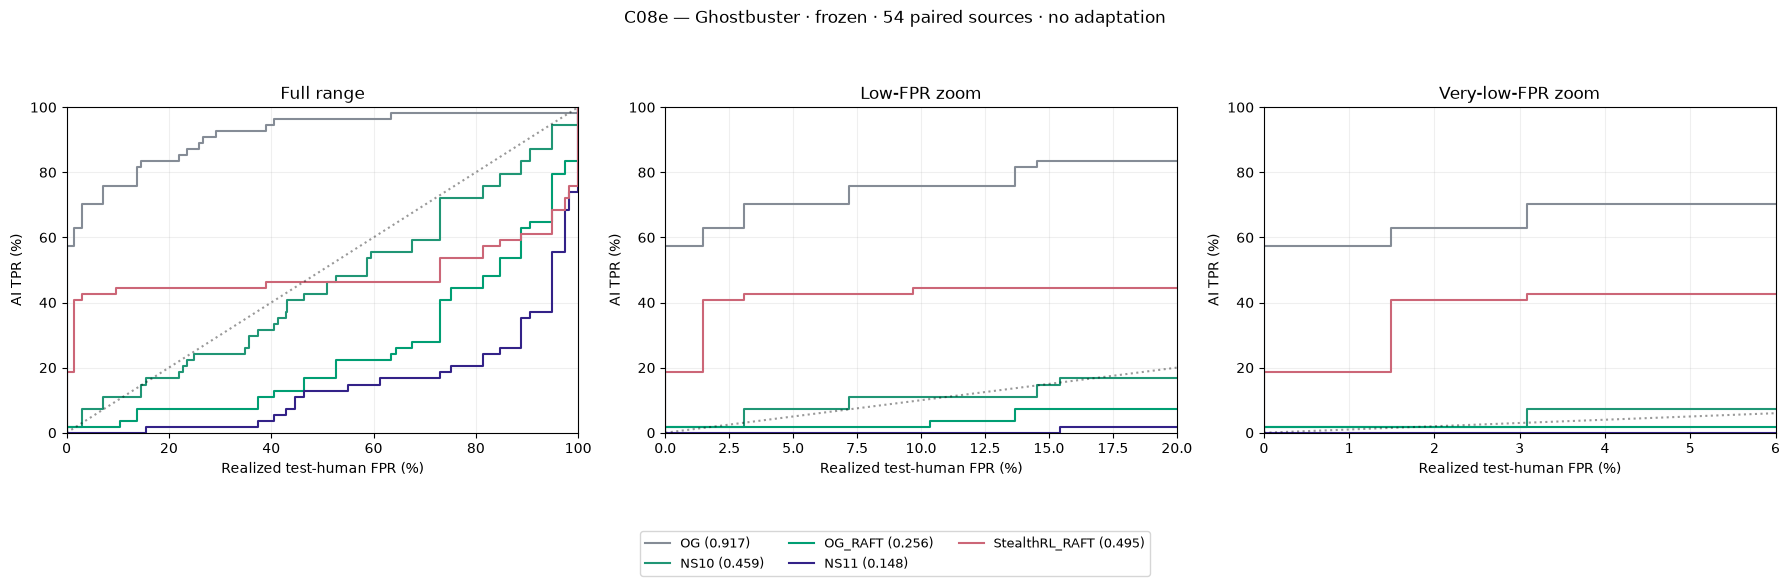

In [9]:
def gb_prior(r):
    matches=raid.loc[raid.text_sha.eq(r.text_sha)]
    if len(matches):
        sid=matches.source_id.iloc[0];v=GB.rf.loc['raid::'+sid,GB.names].to_numpy(float)
        return dict(text_sha=r.text_sha,AI_score=float(GB.predict([v])[0]))
    z=read_json(GB.path(r.text,'features'))
    if z is not None:return dict(text_sha=r.text_sha,AI_score=float(GB.predict([z['features']])[0]))
    return None

def gb_missing(f,save):
    for start in range(0,len(f),128):
        batch=f.iloc[start:start+128];values=GB.score(batch.text,purpose='C08e_final_evaluation')
        for h,v in zip(batch.text_sha,values):save(dict(text_sha=h,AI_score=float(v)))
with run_lock():
    cached_scoring('Ghostbuster',dict(frozen=FROZEN_HASHES,runtime=RUNTIME),gb_missing,gb_prior)
GB.trigram=None;release();report('Ghostbuster')


## 7. Frozen WaveDetect — evaluation only
Same saved C07 checkpoint and C08d inference architecture; no continuation or adaptation.

In [10]:
class WaveletTransform(nn.Module):
    """
    Differentiable continuous wavelet transform (Morlet basis) with padding,
    cropping, and reconstruction.
    Inputs:
        token_probs (B, T)
        attention_mask (B, T) — optional but recommended
    Output:
        wavelet_spectrum (B, 1, num_scales, T)
    """
    def __init__(self, wavelet="morl", num_scales=32, kernel_size=128):
        super().__init__()
        assert wavelet == "morl", "Only Morlet wavelet is supported at this time"
        self.num_scales = num_scales
        self.kernel_size = kernel_size

        # Time axis in [-2, 2]
        self.register_buffer("time", torch.linspace(-2, 2, steps=kernel_size))
        self.sigma = 1.0
        self.freq0 = 5.0
        self.register_buffer("scales", torch.linspace(1.0, num_scales, num_scales))

    def morlet_wavelet(self, scale):
        t = self.time / scale
        wave = torch.exp(-0.5 * (t / self.sigma) ** 2) * torch.cos(2 * math.pi * self.freq0 * t)
        wave = wave / (wave.abs().sum() + 1e-6)
        return wave.view(1, 1, -1)

    def forward(self, token_probs: torch.FloatTensor, attention_mask: torch.FloatTensor = None):
        """
        token_probs: (B, T)
        attention_mask: (B, T)
        return: wavelet_spectrum (B, 1, num_scales, T)
        """
        B, T = token_probs.shape
        device = token_probs.device

        if attention_mask is not None:
            # Compute the valid sequence length for each sample
            valid_lengths = attention_mask.sum(dim=1).long()
        else:
            valid_lengths = torch.full((B,), T, dtype=torch.long, device=device)

        # ========== Wavelet transform ==========
        responses = []
        for i in range(B):
            valid_len = valid_lengths[i].item()
            x_valid = token_probs[i, :valid_len].unsqueeze(0).unsqueeze(0)  # (1, 1, valid_len)
            res_list = []
            for s in self.scales:
                kernel = self.morlet_wavelet(s.to(device)).to(x_valid.dtype)
                pad = self.kernel_size // 2
                conv_real = torch.nn.functional.conv1d(x_valid, kernel, padding=pad)
                res_list.append(conv_real)
            # Stack responses into shape (1, 1, num_scales, valid_len)
            res = torch.stack(res_list, dim=2)
            
            # Restore the original length T by padding zeros on the right
            if valid_len < T:
                pad_size = T - valid_len
                res = torch.nn.functional.pad(res, (0, pad_size))
            responses.append(res)

        responses = torch.cat(responses, dim=0)  # (B, 1, num_scales, T)
        energy = responses.abs()

        return energy

class RaidWaveDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.qwen_model=AutoModelForCausalLM.from_pretrained(snapshot,torch_dtype=torch.bfloat16,
                                                          attn_implementation='sdpa')
        self.qwen_model.config.use_cache=False
        self.qwen_model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant':False})
        self.wavelet=WaveletTransform(num_scales=16,kernel_size=128)
        cfg=ResNetConfig(num_channels=3,embedding_size=64,hidden_sizes=[64,128,256,512],
                         depths=[2,2,2,2],layer_type='basic',hidden_act='relu',downsample_in_first_stage=False)
        self.cnn=ResNetModel(cfg)
        self.classifier=nn.Linear(512,2)
        self.stage=1
    def set_stage(self,stage):
        self.stage=stage
        self.qwen_model.requires_grad_(stage==2)
    def train(self,mode=True):
        super().train(mode)
        if self.stage==1: self.qwen_model.eval()
        return self
    def projected_probs(self,h,y):
        logits=self.qwen_model.lm_head(h).float()
        return logits.log_softmax(-1).gather(-1,y.unsqueeze(-1)).squeeze(-1).exp()
    def forward(self,input_ids,attention_mask):
        with torch.set_grad_enabled(self.training and self.stage==2):
            h=self.qwen_model.model(input_ids=input_ids,attention_mask=attention_mask,
                                    use_cache=False,return_dict=True).last_hidden_state[:,:-1]
            target=input_ids[:,1:]
            chunks=[]
            for start in range(0,h.shape[1],64):
                args=(h[:,start:start+64],target[:,start:start+64])
                if self.training and self.stage==2:
                    prob=checkpoint(self.projected_probs,*args,use_reentrant=False)
                else: prob=self.projected_probs(*args)
                chunks.append(prob)
            mask=attention_mask[:,:-1]
            probs=torch.cat(chunks,dim=1)*mask
        spectrum=self.wavelet(probs,mask).repeat(1,3,1,1)
        out=self.cnn(spectrum,return_dict=True).last_hidden_state.mean(dim=(2,3))
        return self.classifier(out)

WaveDetect : 543 cached; 54 new unique texts


Frozen WaveDetect: 100%|███████████████████████████████████████████████████████████████████████████████████| 54/54 [00:05<00:00, 10.09it/s]


,detector,arm,cases,AUROC,mean_AI_score
0,WaveDetect,OG,54,0.797419,0.706225
1,WaveDetect,NS10,54,0.548795,0.487428
2,WaveDetect,OG_RAFT,54,0.586806,0.475397
3,WaveDetect,NS11,54,0.253375,0.237107
4,WaveDetect,StealthRL_RAFT,54,0.693185,0.511203
5,WaveDetect,StealthRL,54,0.775439,0.587493


,arm,baseline,delta_AUROC,ci_low,ci_high
0,StealthRL_RAFT,StealthRL,-0.082254,-0.142751,-0.028935
1,StealthRL_RAFT,OG,-0.104234,-0.208611,-0.002654
2,StealthRL_RAFT,NS10,0.144390,0.023240,0.264453
3,StealthRL_RAFT,OG_RAFT,0.106379,0.003832,0.207415
4,StealthRL_RAFT,NS11,0.439809,0.335474,0.536594


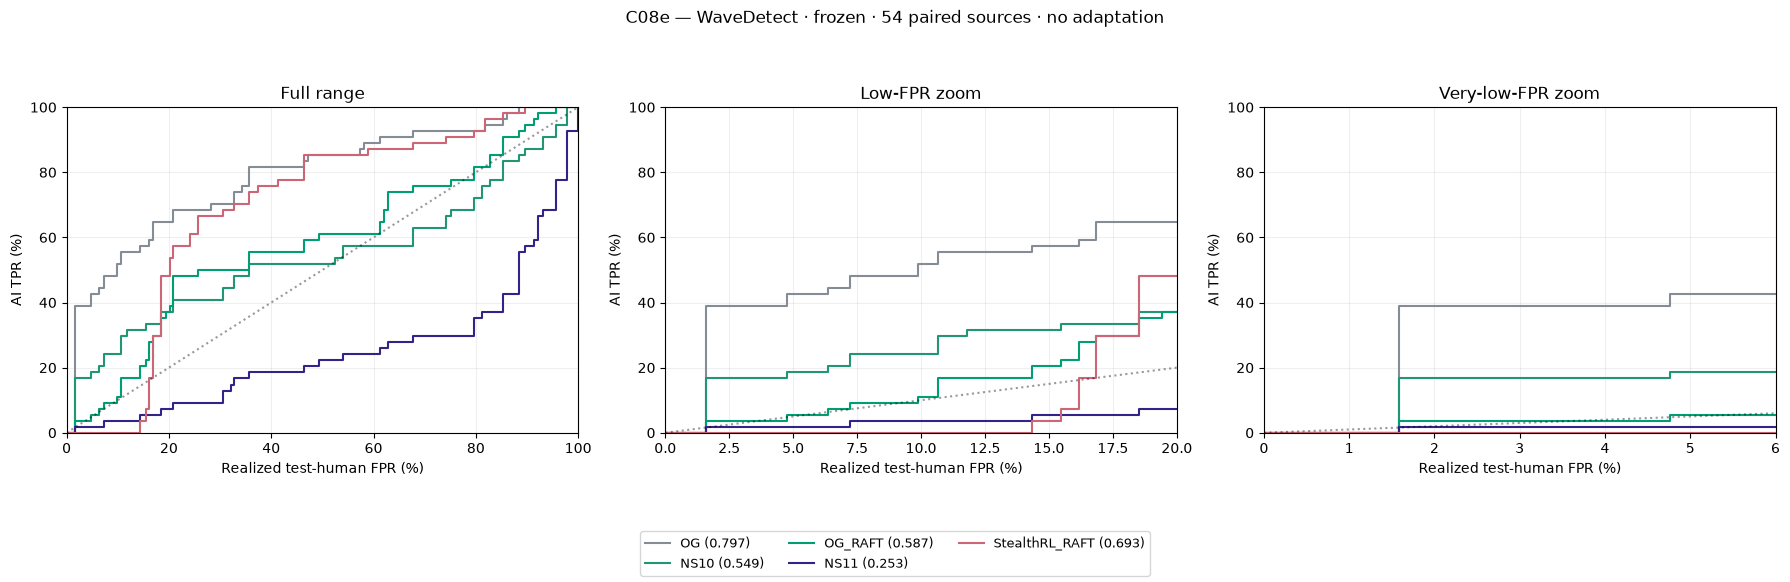

In [11]:
WAVE=R/'C07_WaveDetect_RAID_OG_NS10_v1';W_CP=WAVE/'wavedetect_raid_best.pt'
w_contract=read_json(WAVE/'contract.json');w_oldsha=sha(json.dumps(w_contract,sort_keys=True));w_hash=file_sha(W_CP)
w_pin=read_json(WAVE/'base_revision.json');w_revision=w_pin['revision']
# Exact architecture from C08d is embedded in the preceding definition cell.
w_spec=dict(weights=w_hash,original_contract=w_contract,base_revision=w_revision,max_length=1024,
            torch=str(torch.__version__),transformers=transformers.__version__,precision='BF16 base; FP32 CNN; BF16 autocast',version=1)
w_old=R/'C08d_WaveDetect_competitors_RAFT_NS11_v1';old_wc=read_json(w_old/'contract.json')
w_compatible=old_wc is not None and old_wc.get('frozen_sha')==w_hash and old_wc.get('original_contract')==w_contract and old_wc.get('torch')==str(torch.__version__) and old_wc.get('transformers')==transformers.__version__
w_records={}
if w_compatible:
    aliases={'StealthRL':'StealthRL_RELEASED_4B'}
    for arm in ['RAID_eval','OG','NS10','OG_RAFT','NS11','StealthRL']:
        p=w_old/(aliases.get(arm,arm)+'_scores.csv')
        if p.exists():
            for z in pd.read_csv(p,keep_default_na=False).to_dict('records'):
                if z.get('model_key')==w_hash:w_records[z['text_sha']]=z

def wave_prior(r):return w_records.get(r.text_sha)
def wave_missing(f,save):
    global snapshot
    model=None
    try:
        snapshot=Path(snapshot_download('Qwen/Qwen2.5-0.5B',revision=w_revision))
        tok=AutoTokenizer.from_pretrained(snapshot)
        if tok.pad_token_id is None:tok.pad_token=tok.eos_token
        tok.padding_side='right'
        model=RaidWaveDetect().to(DEVICE)
        obj=torch.load(W_CP,map_location='cpu',weights_only=False);assert obj['contract']==w_oldsha
        model.load_state_dict(obj['model']);model.set_stage(2);model.eval();del obj;release()
        for r in tqdm(f.itertuples(index=False),total=len(f),desc='Frozen WaveDetect'):
            ids=tok(r.text,add_special_tokens=True)['input_ids'];total=len(ids);assert total>=2
            ids=ids[:1024];n=len(ids)
            enc={'input_ids':torch.tensor([ids+[tok.pad_token_id]*(1024-n)],device=DEVICE),'attention_mask':torch.tensor([[1]*n+[0]*(1024-n)],device=DEVICE)}
            with torch.inference_mode(),torch.autocast('cuda',dtype=torch.bfloat16):z=model(**enc).float()
            save(dict(text_sha=r.text_sha,AI_score=float(z.softmax(-1)[0,1].cpu()),total_tokens=total,scored_tokens=n,truncated=total>1024))
    finally:del model;release()
with run_lock():cached_scoring('WaveDetect',w_spec,wave_missing,wave_prior)
report('WaveDetect')


## 8. Frozen RoBERTa — the shared RAFT guide
OG→RAFT, NS11 and the new composition all use the same frozen RoBERTa for ranking and candidate selection.

RoBERTa : 543 cached; 54 new unique texts


Frozen RoBERTa: 100%|██████████████████████████████████████████████████████████████████████████████████████| 54/54 [00:00<00:00, 99.53it/s]


,detector,arm,cases,AUROC,mean_AI_score
0,RoBERTa,OG,54,0.991550,0.943297
1,RoBERTa,NS10,54,0.732803,0.174755
2,RoBERTa,OG_RAFT,54,0.591428,0.158791
3,RoBERTa,NS11,54,0.258950,0.024800
4,RoBERTa,StealthRL_RAFT,54,0.699268,0.103327
5,RoBERTa,StealthRL,54,0.963503,0.664547


,arm,baseline,delta_AUROC,ci_low,ci_high
0,StealthRL_RAFT,StealthRL,-0.264234,-0.350897,-0.188102
1,StealthRL_RAFT,OG,-0.292282,-0.383401,-0.211965
2,StealthRL_RAFT,NS10,-0.033534,-0.113797,0.049828
3,StealthRL_RAFT,OG_RAFT,0.107841,0.038806,0.176761
4,StealthRL_RAFT,NS11,0.440318,0.354399,0.523323


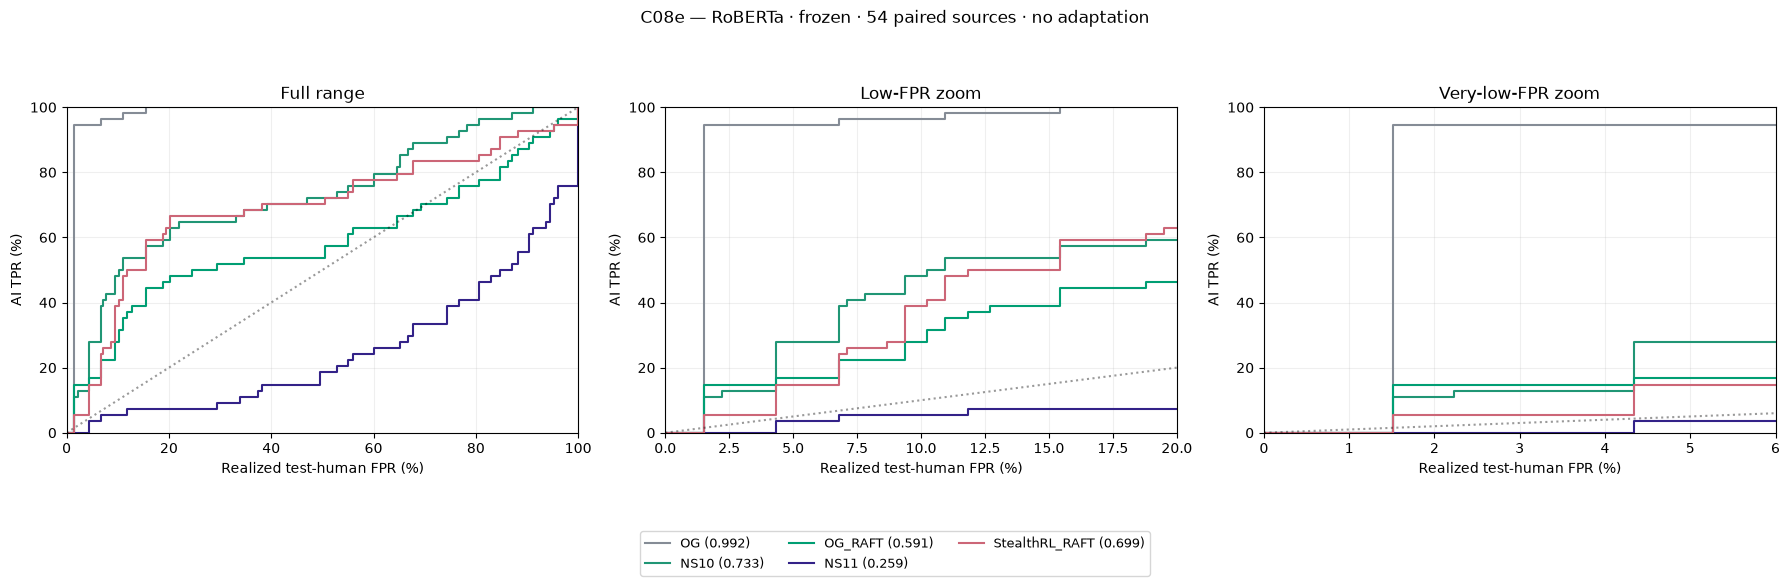

In [12]:
FROZEN_R=R/'C07b_RoBERTa_RAID_OG_NS10_v1/best_model'
rt3={k:RUNTIME[k] for k in ['torch','transformers','accelerate']}
r_spec=dict(weights=fingerprint(FROZEN_R),runtime=rt3,max_tokens=512,attention='eager',precision='fp32_parameters_bf16_autocast',positive_class=1,
    tokenizer_files={p.name:file_sha(p) for p in sorted(FROZEN_R.iterdir()) if p.name in ['tokenizer.json','tokenizer_config.json','special_tokens_map.json','vocab.json','merges.txt']})
r_sig=sha(json.dumps(r_spec,sort_keys=True));old_r=R/'C08b_RoBERTa_competitors_RAFT_NS11_v1/scores'/r_sig

def roberta_prior(r):
    p=old_r/(r.text_sha+'.json')
    if read_json(old_r/'spec.json')==r_spec:return read_json(p)
    return None

def roberta_missing(f,save):
    model=None
    try:
        tok=AutoTokenizer.from_pretrained(FROZEN_R,use_fast=True);tok.truncation_side='right'
        model=AutoModelForSequenceClassification.from_pretrained(FROZEN_R,torch_dtype=torch.float32,attn_implementation='eager',low_cpu_mem_usage=True).to(DEVICE).eval()
        assert model.config.num_labels==2 and torch.cuda.is_bf16_supported()
        for r in tqdm(f.itertuples(index=False),total=len(f),desc='Frozen RoBERTa'):
            ids=tok(r.text,return_tensors='pt',truncation=True,max_length=512).to(DEVICE)
            with torch.inference_mode(),torch.autocast('cuda',dtype=torch.bfloat16):z=model(**ids).logits.float()
            save(dict(text_sha=r.text_sha,AI_score=float(z.softmax(-1)[0,1].cpu()),scored_tokens=int(ids.input_ids.shape[1])))
    finally:del model;release()
with run_lock():cached_scoring('RoBERTa',r_spec,roberta_missing,roberta_prior)
report('RoBERTa')


## 9. Frozen GLTR-feature classifier — evaluation only

GLTR : 543 cached; 54 new unique texts


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Frozen GLTR features: 100%|████████████████████████████████████████████████████████████████████████████████| 54/54 [00:00<00:00, 63.91it/s]


,detector,arm,cases,AUROC,mean_AI_score
0,GLTR,OG,54,0.815979,0.650457
1,GLTR,NS10,54,0.506231,-0.696831
2,GLTR,OG_RAFT,54,0.320135,-1.476803
3,GLTR,NS11,54,0.096642,-2.721266
4,GLTR,StealthRL_RAFT,54,0.099110,-4.602298
5,GLTR,StealthRL,54,0.309175,-2.479841


,arm,baseline,delta_AUROC,ci_low,ci_high
0,StealthRL_RAFT,StealthRL,-0.210065,-0.276267,-0.149122
1,StealthRL_RAFT,OG,-0.716869,-0.788107,-0.640908
2,StealthRL_RAFT,NS10,-0.407121,-0.489665,-0.320484
3,StealthRL_RAFT,OG_RAFT,-0.221025,-0.277879,-0.166938
4,StealthRL_RAFT,NS11,0.002469,-0.052360,0.065390


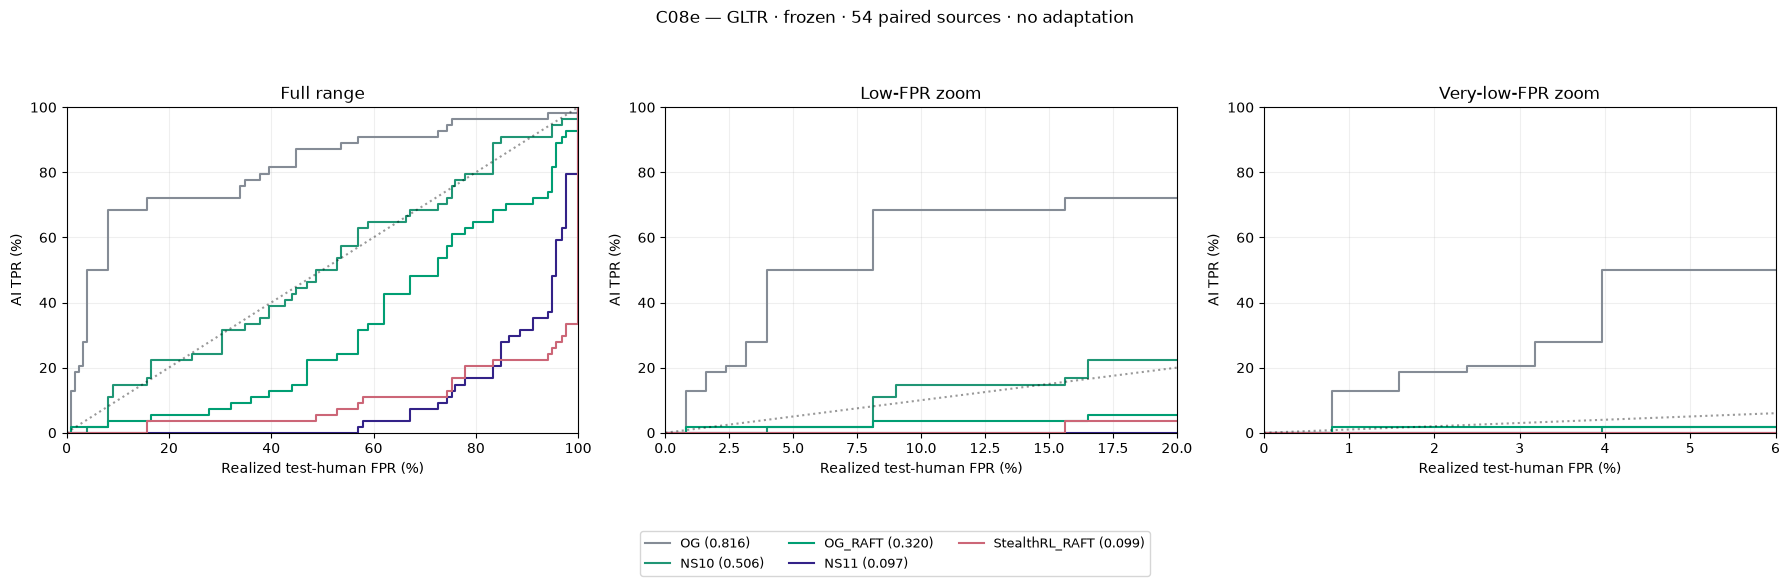

In [13]:
import joblib
GLTR=R/'C07c_GLTR_RAID_OG_NS10_v1'
g_bundle=joblib.load(GLTR/'classifiers.joblib') # trusted project artifact
FEATURES=['rank_1_10','rank_11_100','rank_101_1000','rank_gt_1000']
assert g_bundle['features']==FEATURES
g_scaler=g_bundle['scaler'];g_head=g_bundle['heads']['Frozen / RAID-only']
assert list(g_head.classes_)==[0,1]
g_pin=read_json(GLTR/'model_pin.json')
g_spec={**g_pin,'max_tokens':1024,'dtype':'float32','first_token':'excluded','rank':'1 + number of strictly greater logits','version':1,'transformers':transformers.__version__,'torch':str(torch.__version__)}
def g_feature(text):
    name=sha(json.dumps(g_spec,sort_keys=True)+sha(text))+'.json'
    for base in [GLTR,R/'C08c_GLTR_competitors_RAFT_NS11_v1']:
        p=base/'features'/name
        if p.exists():
            z=read_json(p);assert z['text_sha']==sha(text);return z
    return None

def gltr_prior(r):
    z=g_feature(r.text)
    if z is not None:
        x=pd.DataFrame([z])[FEATURES]
        return dict(text_sha=r.text_sha,AI_score=float(g_head.decision_function(g_scaler.transform(x))[0]))
    return None

def gltr_missing(f,save):
    model=None
    try:
        tok=AutoTokenizer.from_pretrained(g_pin['model'],revision=g_pin['revision'])
        model=AutoModelForCausalLM.from_pretrained(g_pin['model'],revision=g_pin['revision'],torch_dtype=torch.float32,attn_implementation='eager').to(DEVICE).eval()
        for r in tqdm(f.itertuples(index=False),total=len(f),desc='Frozen GLTR features'):
            ids=tok.encode(r.text,add_special_tokens=False,truncation=False);total=len(ids);ids=ids[:1024];assert len(ids)>=2
            batch=torch.tensor([ids],device=DEVICE);counts=np.zeros(4,dtype=np.int64)
            with torch.inference_mode():
                logits=model(input_ids=batch,use_cache=False).logits[0,:-1]
                for start in range(0,len(ids)-1,32):
                    z=logits[start:start+32].float();target=batch[0,start+1:start+1+len(z)];actual=z.gather(1,target[:,None]);ranks=1+(z>actual).sum(dim=1)
                    counts+=np.array([(ranks<=10).sum().item(),((ranks>10)&(ranks<=100)).sum().item(),((ranks>100)&(ranks<=1000)).sum().item(),(ranks>1000).sum().item()])
                del logits,z,target,actual,ranks,batch
            assert counts.sum()==len(ids)-1
            x=pd.DataFrame([counts/counts.sum()],columns=FEATURES)
            score=float(g_head.decision_function(g_scaler.transform(x))[0])
            save(dict(text_sha=r.text_sha,AI_score=score,total_tokens=total,scored_tokens=len(ids)-1,truncated=total>1024,**x.iloc[0].to_dict()))
    finally:del model;release()
with run_lock():cached_scoring('GLTR',dict(extractor=g_spec,classifier=file_sha(GLTR/'classifiers.joblib')),gltr_missing,gltr_prior)
report('GLTR')


## 10. Frozen Binoculars NF4 ratio — evaluation only
Uses the saved Falcon revisions and the same 512-token, BF16/NF4 protocol. Compatible historical caches are reused. A runtime change recomputes needed scores in a separate C08e cache rather than mixing them with the old scores. Only one Falcon is loaded at a time; observer logits are saved to disk and removed after durable final scores.

In [14]:
# Default metric functions from the pinned official implementation (see reference above).
import numpy as np
import torch
import transformers

ce_loss_fn = torch.nn.CrossEntropyLoss(reduction="none")
softmax_fn = torch.nn.Softmax(dim=-1)


def perplexity(encoding: transformers.BatchEncoding,
               logits: torch.Tensor,
               median: bool = False,
               temperature: float = 1.0):
    shifted_logits = logits[..., :-1, :].contiguous() / temperature
    shifted_labels = encoding.input_ids[..., 1:].contiguous()
    shifted_attention_mask = encoding.attention_mask[..., 1:].contiguous()

    if median:
        ce_nan = (ce_loss_fn(shifted_logits.transpose(1, 2), shifted_labels).
                  masked_fill(~shifted_attention_mask.bool(), float("nan")))
        ppl = np.nanmedian(ce_nan.cpu().float().numpy(), 1)

    else:
        ppl = (ce_loss_fn(shifted_logits.transpose(1, 2), shifted_labels) *
               shifted_attention_mask).sum(1) / shifted_attention_mask.sum(1)
        ppl = ppl.to("cpu").float().numpy()

    return ppl


def entropy(p_logits: torch.Tensor,
            q_logits: torch.Tensor,
            encoding: transformers.BatchEncoding,
            pad_token_id: int,
            median: bool = False,
            sample_p: bool = False,
            temperature: float = 1.0):
    vocab_size = p_logits.shape[-1]
    total_tokens_available = q_logits.shape[-2]
    p_scores, q_scores = p_logits / temperature, q_logits / temperature

    p_proba = softmax_fn(p_scores).view(-1, vocab_size)

    if sample_p:
        p_proba = torch.multinomial(p_proba.view(-1, vocab_size), replacement=True, num_samples=1).view(-1)

    q_scores = q_scores.view(-1, vocab_size)

    ce = ce_loss_fn(input=q_scores, target=p_proba).view(-1, total_tokens_available)
    padding_mask = (encoding.input_ids != pad_token_id).type(torch.uint8)

    if median:
        ce_nan = ce.masked_fill(~padding_mask.bool(), float("nan"))
        agg_ce = np.nanmedian(ce_nan.cpu().float().numpy(), 1)
    else:
        agg_ce = (((ce * padding_mask).sum(1) / padding_mask.sum(1)).to("cpu").float().numpy())

    return agg_ce

def save_tensor(obj,path):
 fd,tmp=tempfile.mkstemp(dir=path.parent,suffix='.tmp');os.close(fd)
 try:
  torch.save(obj,tmp)
  with open(tmp,'rb') as f:os.fsync(f.fileno())
  os.replace(tmp,path)
 finally:
  if os.path.exists(tmp):os.unlink(tmp)
def load_model(name):
 print('Loading',name,flush=True)
 quant=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',
  bnb_4bit_use_double_quant=True,bnb_4bit_compute_dtype=torch.bfloat16)
 model=AutoModelForCausalLM.from_pretrained(name,revision=revisions[name],
  torch_dtype=torch.bfloat16,quantization_config=quant,device_map={'':0},
  low_cpu_mem_usage=True,attn_implementation='eager')
 print(f'Model footprint: {model.get_memory_footprint()/2**30:.2f} GiB',flush=True)
 model.eval();return model
@torch.inference_mode()
def forward(model,encoding):
 # Accelerate dispatch hooks move inputs to the execution device as necessary.
 device=model.get_input_embeddings().weight.device
 if device.type=='meta':device=torch.device('cuda:0')
 return model(**{k:v.to(device) for k,v in encoding.items()},use_cache=False).logits.detach().cpu()



Binoculars : 543 cached; 54 new unique texts
Loading tiiuae/falcon-7b


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Loading checkpoint shards: 100%|█████████████████████████████████████████████████████████████████████████████| 2/2 [00:06<00:00,  3.50s/it]

Model footprint: 3.65 GiB



Falcon observer: 100%|█████████████████████████████████████████████████████████████████████████████████████| 16/16 [00:03<00:00,  5.10it/s]


Loading tiiuae/falcon-7b-instruct


...

Loading checkpoint shards: 100%|█████████████████████████████████████████████████████████████████████████████| 2/2 [00:06<00:00,  3.21s/it]

Model footprint: 3.65 GiB



Falcon performer: 100%|██████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:01<00:00,  3.73it/s]


,detector,arm,cases,AUROC,mean_AI_score
0,Binoculars,OG,54,0.905163,-0.765013
1,Binoculars,NS10,54,0.721606,-0.919246
2,Binoculars,OG_RAFT,54,0.661527,-0.955590
3,Binoculars,NS11,54,0.534750,-0.979045
4,Binoculars,StealthRL_RAFT,54,0.155653,-1.132239
5,Binoculars,StealthRL,54,0.381898,-1.031138


,arm,baseline,delta_AUROC,ci_low,ci_high
0,StealthRL_RAFT,StealthRL,-0.226245,-0.312520,-0.148343
1,StealthRL_RAFT,OG,-0.749510,-0.834881,-0.655247
2,StealthRL_RAFT,NS10,-0.565954,-0.674062,-0.458821
3,StealthRL_RAFT,OG_RAFT,-0.505874,-0.600061,-0.410993
4,StealthRL_RAFT,NS11,-0.379097,-0.481589,-0.278918


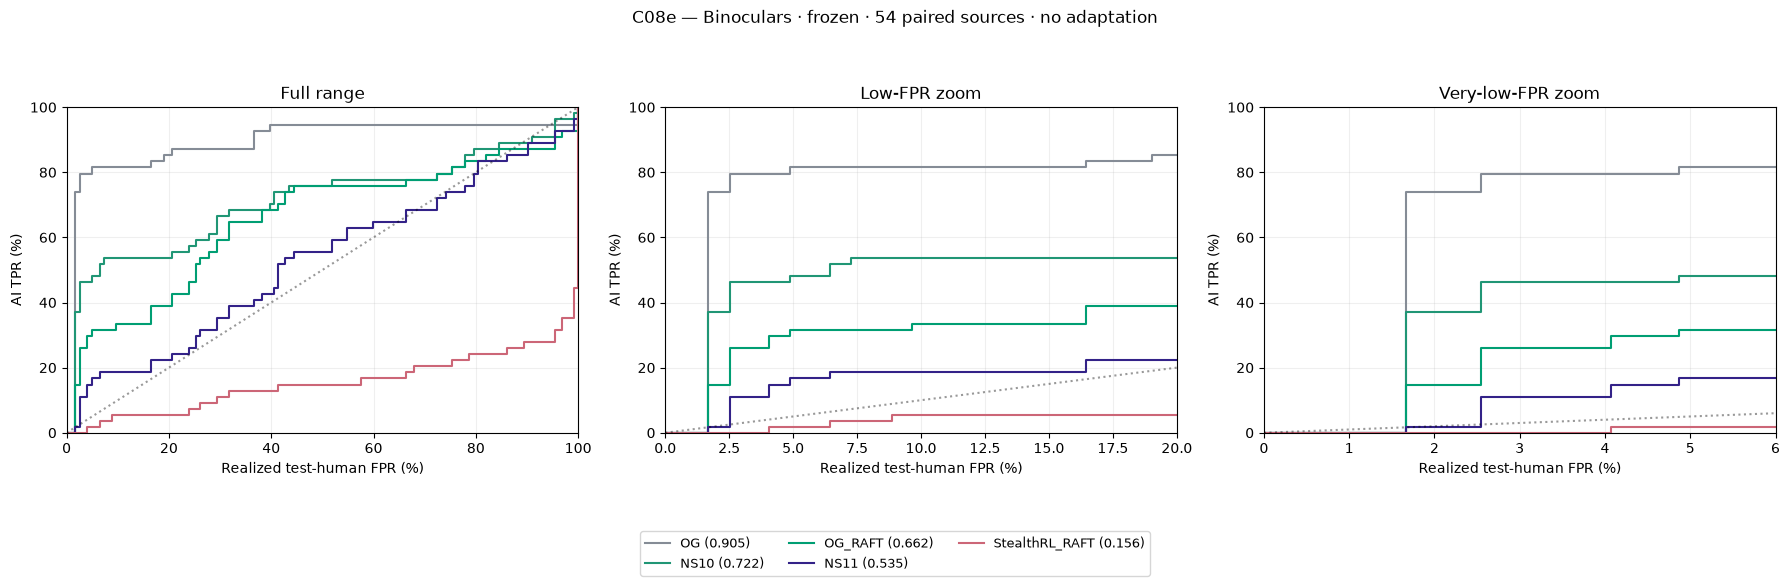

In [15]:
# Same NF4 ratio as C08a. One Falcon at a time; bounded observer logits on disk.
B_OLD=next((R/n for n in ['C07a_Binoculars_NF4_OG_NS10_pinned_v1','C07a_Binoculars_NF4_OG_NS10_v1'] if (R/n/'contract.json').exists()),None)
assert B_OLD is not None,'Restore the completed C07a NF4 run.'
b_oldcontract=read_json(B_OLD/'contract.json');revisions=read_json(B_OLD/'model_revisions.json')
assert revisions==b_oldcontract['models']
OBSERVER='tiiuae/falcon-7b';PERFORMER='tiiuae/falcon-7b-instruct';MAX_TOKENS=512
assert b_oldcontract['max_tokens']==512 and b_oldcontract['quantization']=='NF4_double_quant' and b_oldcontract['metric_device']=='cpu'
assert b_oldcontract['metric']=='official_mean_nll_over_cross_entropy' and b_oldcontract['dtype']=='bfloat16'
assert torch.cuda.is_bf16_supported()
b_contract={**b_oldcontract,'runtime':RUNTIME}
b_signature=sha(json.dumps(b_contract,sort_keys=True))
b_oldsignature=sha(json.dumps(b_oldcontract,sort_keys=True))
b_compatible=(b_contract==b_oldcontract)
if not b_compatible:
    print('Binoculars runtime differs from saved run. Recomputing required scores in C08e; original cache is untouched.')
    display(pd.DataFrame({'saved':b_oldcontract['runtime'],'current':RUNTIME}))
B_WORK=OUT/'evaluation/Binoculars/logits'/b_signature;B_WORK.mkdir(parents=True,exist_ok=True)
SCORE_BATCH_SIZE=16 # disk batch, GPU batch remains 1; decrease for limited disk space

def bino_prior(r):
    if b_compatible:
        z=read_json(B_OLD/'responses'/(sha(b_oldsignature+r.text_sha)+'.json'))
        if z is not None:
            assert z['contract']==b_oldsignature and z['text_sha']==r.text_sha
            return z
    return None

def bino_missing(f,save):
    tok=AutoTokenizer.from_pretrained(OBSERVER,revision=revisions[OBSERVER])
    other=AutoTokenizer.from_pretrained(PERFORMER,revision=revisions[PERFORMER]);assert tok.vocab==other.vocab;del other
    if tok.pad_token is None:tok.pad_token=tok.eos_token
    tok.truncation_side='right'
    def enc(text):return tok(text,return_tensors='pt',truncation=True,max_length=MAX_TOKENS)
    lengths={r.text_sha:len(tok(r.text,truncation=False)['input_ids']) for r in f.itertuples(index=False)}
    assert min(lengths.values())>=2
    vocab=AutoConfig.from_pretrained(OBSERVER,revision=revisions[OBSERVER]).vocab_size
    for start in range(0,len(f),SCORE_BATCH_SIZE):
        batch=f.iloc[start:start+SCORE_BATCH_SIZE]
        pending=[r for r in batch.itertuples(index=False) if not (B_WORK/(r.text_sha+'.pt')).exists()]
        needed=sum(min(lengths[r.text_sha],512)*vocab*4 for r in pending)
        assert shutil.disk_usage(B_WORK).free>needed+2*2**30,'Insufficient disk space; reduce SCORE_BATCH_SIZE.'
        model=None
        try:
            if pending:model=load_model(OBSERVER)
            for r in tqdm(pending,desc='Falcon observer'):
                ids=enc(r.text);logits=forward(model,ids)
                save_tensor(dict(contract=b_signature,text_sha=r.text_sha,ids=ids.input_ids,logits=logits),B_WORK/(r.text_sha+'.pt'))
                del logits,ids
        finally:del model;release()
        model=None
        try:
            model=load_model(PERFORMER)
            for r in tqdm(batch.itertuples(index=False),total=len(batch),desc='Falcon performer'):
                pth=B_WORK/(r.text_sha+'.pt');saved=torch.load(pth,map_location='cpu',weights_only=True);ids=enc(r.text)
                assert saved['contract']==b_signature and saved['text_sha']==r.text_sha and torch.equal(saved['ids'],ids.input_ids)
                q=forward(model,ids);p=saved['logits']
                with torch.inference_mode():nll=float(perplexity(ids,q)[0]);ce=float(entropy(p,q,ids,tok.pad_token_id)[0])
                assert np.isfinite(nll) and np.isfinite(ce) and ce>0
                save(dict(text_sha=r.text_sha,AI_score=-nll/ce,Binoculars_score=nll/ce,mean_nll=nll,cross_entropy=ce,
                    total_tokens=lengths[r.text_sha],scored_tokens=int(ids.input_ids.shape[1]),truncated=lengths[r.text_sha]>512))
                pth.unlink();del saved,ids,p,q
        finally:del model;release()
with run_lock():cached_scoring('Binoculars',b_contract,bino_missing,bino_prior)
report('Binoculars')


## 11. Combined report and manual quality inspection
A negative parent contrast means this RAFT composition reduced fixed-detector AUROC relative to StealthRL. Compare the full pattern rather than declaring a universal winner. The RAFT guide and edit procedure are standardized across the compositions; quality and starting-text differences still matter.

In [16]:
tables=[];changes=[]
for name in ['Ghostbuster','WaveDetect','RoBERTa','Binoculars','GLTR']:
    p=OUT/'evaluation'/name
    assert (p/'summary54.csv').exists(),f'Run {name} evaluation first.'
    tables.append(pd.read_csv(p/'summary54.csv'))
    c=pd.read_csv(p/'paired_changes.csv');c['detector']=name;changes.append(c)
all_summary=pd.concat(tables,ignore_index=True);all_changes=pd.concat(changes,ignore_index=True)
csv(all_summary,OUT/'five_detector_summary54.csv');csv(all_changes,OUT/'five_detector_paired_changes.csv')
display(all_summary.pivot(index='arm',columns='detector',values='AUROC').reindex([*PLOT_ARMS,'StealthRL']).round(6))
display(all_changes.loc[all_changes.baseline.eq('StealthRL')].round(6))
quality=frames['StealthRL'][['case_id','domain','text']].rename(columns={'text':'StealthRL_text'}).merge(new[['case_id','text','substitutions']],on='case_id',validate='one_to_one').rename(columns={'text':'StealthRL_RAFT_text'})
csv(quality,OUT/'manual_quality_review54.csv')
print('Saved all results and the side-by-side review:',OUT)
# Inspect any case without changing the saved output or selecting on detector outcomes:
CASE_TO_VIEW=case_ids[0]
r=quality.set_index('case_id').loc[CASE_TO_VIEW]
print('CASE',CASE_TO_VIEW,'\n\nSTEALTHRL:\n',r.StealthRL_text,'\n\nSTEALTHRL → RAFT:\n',r.StealthRL_RAFT_text)


detector,Binoculars,GLTR,Ghostbuster,RoBERTa,WaveDetect
arm,,,,,
OG,0.905163,0.815979,0.917333,0.991550,0.797419
NS10,0.721606,0.506231,0.458931,0.732803,0.548795
OG_RAFT,0.661527,0.320135,0.256362,0.591428,0.586806
NS11,0.534750,0.096642,0.147951,0.258950,0.253375
StealthRL_RAFT,0.155653,0.099110,0.495319,0.699268,0.693185
StealthRL,0.381898,0.309175,0.736657,0.963503,0.775439


,arm,baseline,delta_AUROC,ci_low,ci_high,detector
0,StealthRL_RAFT,StealthRL,-0.241337,-0.335468,-0.148544,Ghostbuster
5,StealthRL_RAFT,StealthRL,-0.082254,-0.142751,-0.028935,WaveDetect
10,StealthRL_RAFT,StealthRL,-0.264234,-0.350897,-0.188102,RoBERTa
15,StealthRL_RAFT,StealthRL,-0.226245,-0.312520,-0.148343,Binoculars
20,StealthRL_RAFT,StealthRL,-0.210065,-0.276267,-0.149122,GLTR


Saved all results and the side-by-side review: ../results/causal/C08e_StealthRL_RAFT_RoBERTaGuide_v1
CASE gate_0001 

STEALTHRL:
 This paper examines power flow in electrical circuits, specifically addressing cases where power surges oppose conventional flow directions—an effect termed inverse power flow.  
(Note: Adjusted flow slightly while keeping meaning.) 

STEALTHRL → RAFT:
 This memo examines power flow in electronic circuits, specifically addressing cases where power surges oppose conventional flow directions—an effect termed inverse power flow. (Note: Adjusted retrograde slightly while keeping meaning.)
